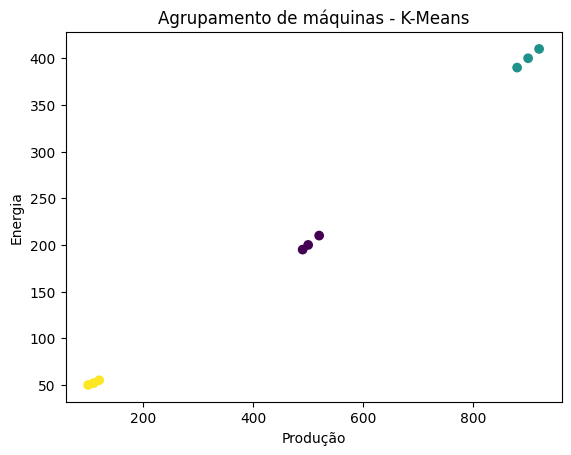

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

dados = {
    "producao": [100, 120, 110, 500, 520, 490,
                 900, 920, 880],
    "energia": [50, 55, 52, 200, 210, 195,
                400, 410, 390]
}

df = pd.DataFrame(dados)

# Padronizar os dados
scaler = StandardScaler()
X = scaler.fit_transform(df[["producao", "energia"]])

# Criar e treinar o modelo
modelo = KMeans(n_clusters=3, random_state=42, n_init=10)
df["grupo"] = modelo.fit_predict(X)

# Visualizar os agrupamentos
plt.scatter(df["producao"], df["energia"],
            c=df["grupo"], cmap="viridis")

plt.xlabel("Produção")
plt.ylabel("Energia")
plt.title("Agrupamento de máquinas - K-Means")
plt.show()

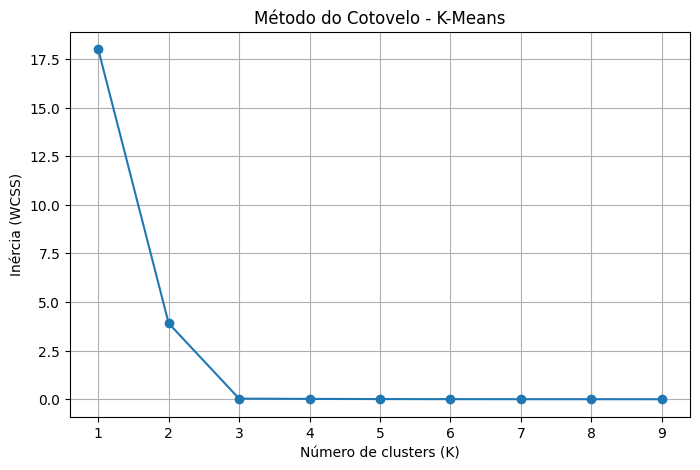

In [ ]:
# Lista para armazenar os valores de inércia
inercias = []

# Testar diferentes quantidades de clusters
for k in range(1, 10):

    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    modelo.fit(X)

    # Armazena a soma dos quadrados das distâncias
    inercias.append(modelo.inertia_)

# Plotar o gráfico do cotovelo
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 10),
    inercias,
    marker="o"
)

plt.xlabel("Número de clusters (K)")
plt.ylabel("Inércia (WCSS)")
plt.title("Método do Cotovelo - K-Means")
plt.xticks(range(1, 10))
plt.grid(True)

plt.show()

In [10]:

# Importa a biblioteca Pandas para criar e manipular tabelas
import pandas as pd

# Importa o Matplotlib para criar gráficos
import matplotlib.pyplot as plt

# Importa o algoritmo K-Means para realizar agrupamentos
from sklearn.cluster import KMeans

# Importa o StandardScaler para padronizar os dados
from sklearn.preprocessing import StandardScaler

In [11]:
# ==========================================
# 1. CRIAÇÃO DO CONJUNTO DE DADOS
# ==========================================

# Dados coletados de nove máquinas industriais
# Cada máquina possui informações de produção e
# consumo de energia elétrica

dados = {
    "maquina": ["M01", "M02", "M03",
                "M04", "M05", "M06",
                "M07", "M08", "M09"],

    "producao": [100, 120, 110, 500, 520, 490,
                 900, 920, 880],

    "energia": [50, 55, 52, 200, 210, 195,
                400, 410, 390]
}

# Converte o dicionário em um DataFrame
df = pd.DataFrame(dados)

# Exibe os dados originais
print("Dados das máquinas:")
print(df)

Dados das máquinas:
  maquina  producao  energia
0     M01       100       50
1     M02       120       55
2     M03       110       52
3     M04       500      200
4     M05       520      210
5     M06       490      195
6     M07       900      400
7     M08       920      410
8     M09       880      390


In [14]:
df.head(10)

,maquina,producao,energia
0,M01,100,50
1,M02,120,55
2,M03,110,52
3,M04,500,200
4,M05,520,210
5,M06,490,195
6,M07,900,400
7,M08,920,410
8,M09,880,390



Dados padronizados:
[[-1.2530436  -1.17868378]
 [-1.19107991 -1.1436039 ]
 [-1.22206175 -1.16465183]
 [-0.01376971 -0.12628755]
 [ 0.04819398 -0.0561278 ]
 [-0.04475156 -0.16136742]
 [ 1.22550418  1.27690742]
 [ 1.28746788  1.34706717]
 [ 1.16354049  1.20674767]]

Resultado dos agrupamentos:
  maquina  producao  energia  grupo  eficiencia
3     M04       500      200      0    2.500000
4     M05       520      210      0    2.476190
5     M06       490      195      0    2.512821
6     M07       900      400      1    2.250000
7     M08       920      410      1    2.243902
8     M09       880      390      1    2.256410
0     M01       100       50      2    2.000000
2     M03       110       52      2    2.115385
1     M02       120       55      2    2.181818


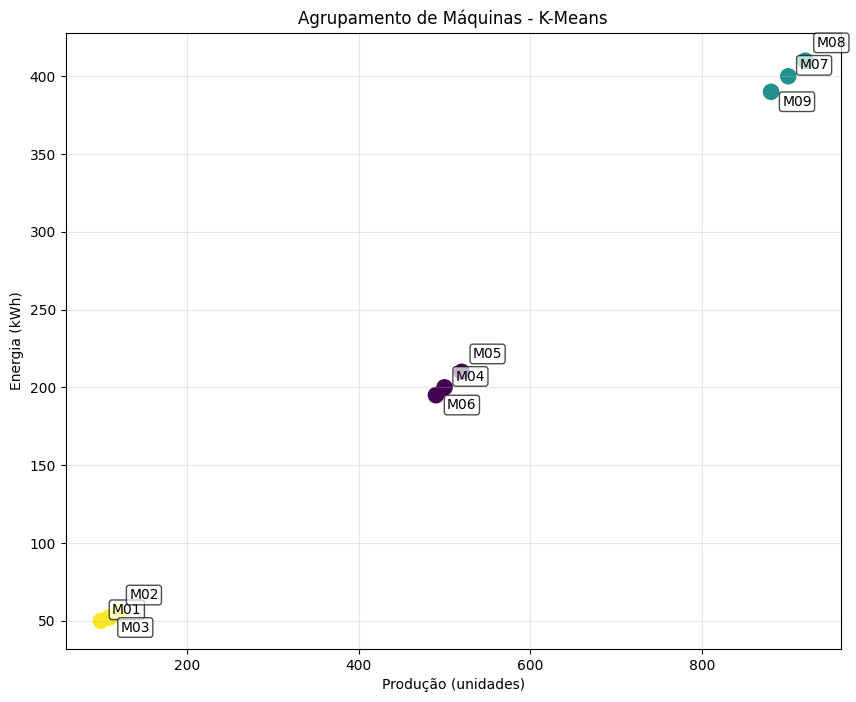

In [15]:
# ==========================================
# 2. PADRONIZAÇÃO DOS DADOS
# ==========================================

# O K-Means utiliza distâncias para agrupar os dados
# Por isso, variáveis com escalas diferentes podem
# influenciar de maneira desigual os agrupamentos

# Cria o objeto responsável pela padronização
scaler = StandardScaler()

# Seleciona as variáveis utilizadas pelo K-Means
# fit_transform():
# fit: calcula a média e o desvio-padrão
# transform: padroniza os valores
#
# Após a padronização:
# Média aproximadamente igual a 0
# Desvio-padrão igual a 1

X = scaler.fit_transform(df[["producao", "energia"]])

# Exibe os dados padronizados
print("\nDados padronizados:")
print(X)


# ==========================================
# 3. CRIAÇÃO DO MODELO K-MEANS
# ==========================================

# Cria o algoritmo de agrupamento K-Means
modelo = KMeans(
    n_clusters=3,    # Quantidade de grupos desejados (K=3)
    random_state=42, # Permite reproduzir os resultados
    n_init=10         # Executa o K-Means 10 vezes com
                      # diferentes inicializações e
                      # seleciona o resultado de menor inércia
)


# ==========================================
# 4. TREINAMENTO E IDENTIFICAÇÃO DOS GRUPOS
# ==========================================

# fit_predict(X):
# fit: treina o algoritmo utilizando os dados padronizados
# predict: identifica a qual grupo cada máquina pertence
#
# Os grupos são identificados por números: 0, 1 e 2
# Esses números não representam uma ordem de desempenho

df["grupo"] = modelo.fit_predict(X)


# ==========================================
# 5. CÁLCULO DA EFICIÊNCIA ENERGÉTICA
# ==========================================

# A eficiência energética indica quantas unidades
# são produzidas para cada kWh consumido
#
# Fórmula:
# Eficiência = Produção / Energia
#
# Quanto maior o resultado, maior a quantidade
# produzida por unidade de energia consumida

df["eficiencia"] = df["producao"] / df["energia"]

# Exibe as máquinas organizadas por grupo
print("\nResultado dos agrupamentos:")
print(df.sort_values("grupo"))


# ==========================================
# 6. VISUALIZAÇÃO DOS AGRUPAMENTOS
# ==========================================

plt.figure(figsize=(10, 8))

plt.scatter(
    df["producao"],
    df["energia"],
    c=df["grupo"],
    cmap="viridis",
    s=120
)

# Deslocamentos manuais para evitar sobreposição dos textos
deslocamentos = {
    "M01": (8, 5),
    "M02": (8, 10),
    "M03": (8, -10),
    "M04": (8, 5),
    "M05": (8, 10),
    "M06": (8, -10),
    "M07": (8, 5),
    "M08": (8, 10),
    "M09": (8, -10)
}

# Adiciona o nome de cada máquina com deslocamento
for i in range(len(df)):
    maquina = df.loc[i, "maquina"]
    x = df.loc[i, "producao"]
    y = df.loc[i, "energia"]

    dx, dy = deslocamentos[maquina]

    plt.annotate(
        maquina,
        (x, y),
        xytext=(dx, dy),
        textcoords="offset points",
        fontsize=10,
        bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7)
    )

plt.xlabel("Produção (unidades)")
plt.ylabel("Energia (kWh)")
plt.title("Agrupamento de Máquinas - K-Means")
plt.grid(alpha=0.3)
plt.show()
# ==========================================
# 7. MÉTODO DO COTOVELO (ELBOW METHOD)
# ==========================================

# O método do cotovelo ajuda a avaliar
# a quantidade adequada de grupos (K)
#
# Ele utiliza a inércia (WCSS), que representa
# a soma das distâncias quadráticas dos pontos
# aos centroides de seus respectivos grupos
#
# Quanto menor a inércia, mais próximos os pontos
# estão dos centroides de seus grupos

# Cria uma lista vazia para armazenar as inércias
inercias = []

# Testa diferentes quantidades de grupos
# range(1, 9) gera valores de K entre 1 e 8
for k in range(1, 9):

    # Cria um novo modelo K-Means para cada valor de K
    modelo_k = KMeans(
        n_clusters=k,     # Quantidade de grupos testada
        random_state=42,  # Mantém a reprodutibilidade
        n_init=10         # Testa 10 inicializações
    )

    # Treina o modelo com os dados padronizados
    modelo_k.fit(X)

    # inertia_ retorna a inércia do modelo treinado
    # append() adiciona esse valor à lista
    inercias.append(modelo_k.inertia_)





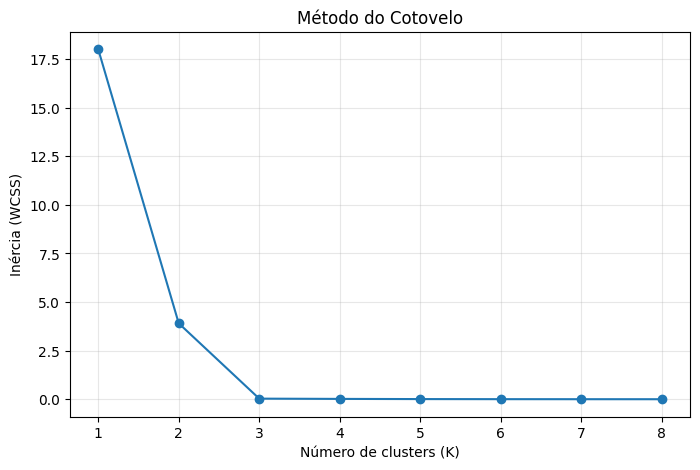

In [9]:
# ==========================================
# 8. GRÁFICO DO MÉTODO DO COTOVELO
# ==========================================

# Define o tamanho do gráfico
plt.figure(figsize=(8, 5))

# Cria um gráfico de linha
# Eixo X: quantidade de grupos (K)
# Eixo Y: valor da inércia
plt.plot(
    range(1, 9),
    inercias,
    marker="o"     # Exibe um marcador em cada valor de K
)

# Define os nomes dos eixos
plt.xlabel("Número de clusters (K)")
plt.ylabel("Inércia (WCSS)")

# Define o título do gráfico
plt.title("Método do Cotovelo")

# Exibe todos os valores de K no eixo X
plt.xticks(range(1, 9))

# Adiciona uma grade
plt.grid(alpha=0.3)

# Exibe o gráfico
plt.show()